# Modeling a "System of X"

##**Demo 1:** (**Breadth** → Synthesis → Discovery)

### Overview
For this demo exercise, you'll focus on one central concept of interest (**diabetic retinopathy**), work out the direction and sign of its best-evidenced relationships, and map the landscape, all via a single API call.

## 0. Setup & Auth

Everything below runs on one API key and one auth header, reused for every call in this notebook. To get started, simply replace `YOUR_API_KEY` with your Beta API key and you're set up for the rest of the walkthrough.

We're also defining three small helpers here that you'll see reused throughout: `get_json` for a single request, `paginate_all` for walking through multi-page results, and `find_exact_concept` for handling a quirk in how concept search ranks results (more on that in Section 1).

In [ ]:
import time
from collections import Counter

import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import requests

API_KEY = "YOUR_API_KEY"  # replace with your beta API key
BASE_URL = "https://public-api.system.com"
HEADERS = {"x-api-key": API_KEY}


def get_json(path, params=None):
    """GET a Public Graph endpoint and return the parsed JSON body."""
    resp = requests.get(f"{BASE_URL}{path}", headers=HEADERS, params=params or {})
    resp.raise_for_status()
    return resp.json()


def paginate_all(path, params=None, page_size=100, max_records=None, sleep_s=0.0):
    """Walk a paginated list endpoint (offset/limit) and return records, up to max_records if set."""
    params = dict(params or {})
    params["limit"] = page_size
    params["include_total"] = True
    offset = 0
    records = []
    total = None
    while total is None or offset < total:
        params["offset"] = offset
        page = get_json(path, params)
        records.extend(page["data"])
        total = page.get("total", len(records))
        offset += page_size
        if sleep_s:
            time.sleep(sleep_s)
        if not page["data"]:
            break
        if max_records and len(records) >= max_records:
            records = records[:max_records]
            break
    return records, total


def find_exact_concept(label, page_size=50, max_records=500):
    """Search concepts by label and return the one whose wikidata_label matches exactly.

    The canonical concept isn't always the top search hit — subtypes and aliases (e.g.
    'background diabetic retinopathy') can outrank it. We page through search results looking
    for an exact (case-insensitive) label match instead of trusting the first few hits.
    """
    hits, _ = paginate_all(
        "/v1/concepts", {"search": f"wikidata_label:{label}"},
        page_size=page_size, max_records=max_records,
    )
    exact = [c for c in hits if c["wikidata_label"].strip().lower() == label.strip().lower()]
    if not exact:
        seen = "\n".join(f"  {c['system_id']} - {c['wikidata_label']}" for c in hits[:20])
        raise ValueError(
            f"No concept with the exact label '{label}' turned up in the first {len(hits)} "
            f"search hits.\nClosest matches seen:\n{seen}\n"
            "Try raising max_records, or pick the right system_id manually from the list above."
        )
    return exact[0]

## 1. Concept lookup

First, you must ground the topic of **diabetic retinopathy** to its canonical concept, which is the anchor for everything that follows.

**Note:** The canonical concept isn't always the top search hit; subtypes like "background diabetic retinopathy" or "severe nonproliferative diabetic retinopathy" can outrank plain "diabetic retinopathy" in the search results. To account for this, use `find_exact_concept()` (defined in Setup) to page through results until it finds an exact label match.

In [4]:
dr_concept = find_exact_concept("diabetic retinopathy")
dr_concept

{'system_id': 'O0vVvNvNdN',
 'wikidata_label': 'diabetic retinopathy',
 'wikidata_id': 'Q631361',
 'wikidata_description': 'human disease',
 'wikidata_aliases': ['diabetic eye disease',
  'retinal abnormality - diabetes-related',
  'diabetes mellitus insulin dependent type, not stated as uncontrolled, with ophthalmic manifestations',
  'diabetes mellitus juvenile type, not stated as uncontrolled, with ophthalmic manifestations',
  'diabetes mellitus type I [insulin dependent type] [IDDM] [juvenile type], not stated as uncontrolled, with ophthalmic manifestations',
  'diabetic oculopathy']}

## 2. Relationship traversal

Next, you'll pull every relationship where **diabetic retinopathy** shows up on either side, to access the full breadth of what the literature links it to.

System caps the pull at `MAX_RECORDS` to keep things fast, but we'll print the *true* total too, so you see the real scale, not just what we chose to show. We'll also tag each relationship with its direction — **diabetic retinopathy** as the source (upstream) vs. **diabetic retinopathy** as the target (downstream) — since the graph treats those as distinct relationships, and we'll reuse that tag throughout.

**Note:** We also set aside self-relationships — e.g., **diabetic retinopathy** related to **diabetic retinopathy**. Those are real records, and for this particular topic are actually the highest-volume relationship, but pulling them would a) draw as a loop on the node itself and b) tell you nothing about the surrounding landscape. However, for documenaton purposes, we always print how many of these self-relationships were dropped.

In [5]:
MAX_RECORDS = 300  # demo-speed cap; raise or remove for a full pull

dr_relationships, true_total = paginate_all(
    f"/v1/concepts/{dr_concept['system_id']}/relationships",
    {"sort": "num_studies:desc"},
    max_records=MAX_RECORDS,
)

# Drop self-relationships (diabetic retinopathy related to itself). These are real records in the
# graph -- and often the highest-volume one -- but they'd render as a self-loop on the
# node and tell us nothing about the landscape, so we set them aside and say how many.
self_loops = [
    r for r in dr_relationships
    if r["source_concept"]["system_id"] == r["target_concept"]["system_id"]
]
dr_relationships = [
    r for r in dr_relationships
    if r["source_concept"]["system_id"] != r["target_concept"]["system_id"]
]


def other_concept(rel):
    """Return whichever side of the relationship isn't diabetic retinopathy."""
    if rel["source_concept"]["system_id"] == dr_concept["system_id"]:
        return rel["target_concept"]
    return rel["source_concept"]


for rel in dr_relationships:
    rel["_other_concept"] = other_concept(rel)
    rel["_direction"] = (
        "upstream" if rel["source_concept"]["system_id"] == dr_concept["system_id"]
        else "downstream"
    )

upstream = [r for r in dr_relationships if r["_direction"] == "upstream"]
downstream = [r for r in dr_relationships if r["_direction"] == "downstream"]

print(f"Graph reports {true_total} total relationships touching diabetic retinopathy.")
print(f"Pulled the top {len(dr_relationships)} (by num_studies) for this demo.")
if self_loops:
    dropped = sum(r["num_studies"] for r in self_loops)
    print(f"  (set aside {len(self_loops)} self-relationship(s), {dropped} studies)")
print(f"  {len(upstream)} upstream (diabetic retinopathy \u2192 concept)")
print(f"  {len(downstream)} downstream (concept \u2192 diabetic retinopathy)")

Graph reports 686 total relationships touching diabetic retinopathy.
Pulled the top 300 (by num_studies) for this demo.
  128 upstream (diabetic retinopathy → concept)
  172 downstream (concept → diabetic retinopathy)


## 3. Provenance

Now, you'll ground a few of these in real papers. First, take the top 5 by evidence volume; then, pull one real supporting finding (plus its study metadata) for each, to show that every connection traces back to a citable source.

**Note:** For the full deep dive on evidence, consult Demo 2 in this series.

In [6]:
TOP_N_PROVENANCE = 5

provenance_rows = []
for rel in dr_relationships[:TOP_N_PROVENANCE]:
    assoc_page = get_json(
        f"/v1/relationships/{rel['relationship_id'].replace('|', '%7C')}/associations",
        {"limit": 1},
    )
    if not assoc_page["data"]:
        continue
    assoc = assoc_page["data"][0]
    study = get_json(f"/v1/studies/{assoc['study_id']}")
    provenance_rows.append({
        "direction": rel["_direction"],
        "connected_concept": rel["_other_concept"]["wikidata_label"],
        "num_studies": rel["num_studies"],
        "example_statistic": f"{assoc['statistic_type']} = {assoc['statistic_value']}",
        "pubmed_id": assoc["pubmed_id"],
        "doi": study.get("doi"),
        "population": study.get("population"),
    })

pd.DataFrame(provenance_rows)

,direction,connected_concept,num_studies,example_statistic,pubmed_id,doi,population
0,downstream,diabetes,138,relative_risk_ratio = 0.7,15878059,10.1016/j.ophtha.2004.11.054,324 participants of the Barbados Eye Studies w...
1,downstream,glycated hemoglobin,65,odds_ratio = 1.269,36194621,10.1371/journal.pone.0275617,7462 Chinese adults with type 2 diabetes melli...
2,downstream,blood pressure,45,odds_ratio = 1.04,24588941,10.1186/1472-6823-14-20,684 adults with young-onset diabetes referred ...
3,downstream,insulin,40,odds_ratio = 0.07,35937830,10.3389/fendo.2022.764254,124 eyes from patients with proliferative diab...
4,downstream,HBA1,36,hazard_ratio = 1.48,35248652,10.1016/j.diabres.2022.109814,123 type 1 diabetic patients followed for 15 y...


## 4. Classification

Now that we know what statistic types actually show up (mostly odds ratios and other ratio-type stats, plus a couple of ambiguous ones), we can classify each of the top relationships as associated with increased risk, decreased risk, or unclear, based on where its reported value falls relative to the statistic's null-effect point (1 for ratios, 0 for differences and correlations).

We sample up to 3 associations per relationship rather than 1 — a single sample risked landing on an atypical statistic type for a well-evidenced relationship purely by chance. Whichever statistic type is most common among the sample (ties broken in favor of a type we can actually map) becomes that relationship's dominant type, and we majority-vote the sign among associations of that type. We only trust statistic types we can map with confidence — `coefficient` and anything we haven't seen before get labeled **unclassified** — and if the sampled associations disagree (one study finds increased risk, another finds decreased), that's labeled "mixed" rather than forced to a side. We also explain exactly why each unclassified or mixed relationship landed there.

In [7]:
TOP_N_FOR_GRAPH = 25
top_for_graph = dr_relationships[:TOP_N_FOR_GRAPH]

STATISTIC_TYPE_REFERENCE = {
    "odds_ratio": 1,
    "adjusted_odds_ratio": 1,
    "relative_risk_ratio": 1,
    "hazard_ratio": 1,
    "adjusted_hazard_ratio": 1,
    "incident_rate_ratio": 1,
    "prevalence_ratio": 1,
    "pearson_r": 0,
    "spearman_correlation": 0,
    "mean_difference_unstandardized": 0,
    "mean_difference_standardized": 0,
    # anything else (including "coefficient", which is too ambiguous to assume
    # a reference point for) falls through to "unclassified" rather than a guess
}


def classify_sign(statistic_type, statistic_value):
    reference = STATISTIC_TYPE_REFERENCE.get(statistic_type)
    if reference is None or statistic_value is None:
        return "unclassified"
    if statistic_value > reference:
        return "increased"
    if statistic_value < reference:
        return "decreased"
    return "null effect"


def classify_relationship(associations):
    """Classify a relationship's sign from up to a few sampled associations.

    Uses whichever statistic_type is most common in the sample (preferring a
    type we can actually map, on ties), then majority-votes the sign among
    associations of that type. Returns 'mixed' if that vote is a genuine tie
    -- real disagreement between studies, not something to hide.
    """
    if not associations:
        return "unclassified", None

    type_counts = Counter(a.get("statistic_type") for a in associations)
    max_count = max(type_counts.values())
    candidates = [t for t, c in type_counts.items() if c == max_count]
    classifiable = [t for t in candidates if t in STATISTIC_TYPE_REFERENCE]
    dominant_type = classifiable[0] if classifiable else candidates[0]

    if dominant_type not in STATISTIC_TYPE_REFERENCE:
        return "unclassified", dominant_type

    signs = [
        classify_sign(dominant_type, a.get("statistic_value"))
        for a in associations if a.get("statistic_type") == dominant_type
    ]
    sign_tally = Counter(signs)
    top_count = max(sign_tally.values())
    top_signs = [s for s, c in sign_tally.items() if c == top_count]
    if len(top_signs) > 1:
        return "mixed", dominant_type
    return top_signs[0], dominant_type


statistic_type_counts = Counter()
sign_counts = Counter()
missing = 0

for rel in top_for_graph:
    assoc_page = get_json(
        f"/v1/relationships/{rel['relationship_id'].replace('|', '%7C')}/associations",
        {"limit": 3},
    )
    associations = assoc_page["data"]
    if not associations:
        missing += 1
    sign, dominant_type = classify_relationship(associations)
    rel["_sign"] = sign
    rel["_statistic_type"] = dominant_type
    if dominant_type:
        statistic_type_counts[dominant_type] += 1
    sign_counts[sign] += 1

print(f"Checked {len(top_for_graph)} relationships ({missing} had no associations to sample).")
print()
print("Dominant statistic_type per relationship:")
for stat, count in statistic_type_counts.most_common():
    print(f"  {stat}: {count}")
print()
print("Sign classification:")
for sign, count in sign_counts.most_common():
    print(f"  {sign}: {count}")

print()
unclassified_rels = [r for r in top_for_graph if r["_sign"] == "unclassified"]
print(f"Why each of the {len(unclassified_rels)} unclassified relationships landed there:")
for r in unclassified_rels:
    reason = (
        "no associations found" if r["_statistic_type"] is None
        else f"dominant statistic_type={r['_statistic_type']!r} not in reference table"
    )
    print(f"  {r['_other_concept']['wikidata_label']} ({r['_direction']}): {reason}")

mixed_rels = [r for r in top_for_graph if r["_sign"] == "mixed"]
if mixed_rels:
    print()
    print(f"{len(mixed_rels)} relationships had genuinely conflicting evidence (mixed):")
    for r in mixed_rels:
        print(f"  {r['_other_concept']['wikidata_label']} ({r['_direction']}), "
              f"statistic_type={r['_statistic_type']!r}")

Checked 25 relationships (1 had no associations to sample).

Dominant statistic_type per relationship:
  odds_ratio: 18
  hazard_ratio: 4
  adjusted_odds_ratio: 1
  mean_difference_unstandardized: 1

Sign classification:
  increased: 23
  decreased: 1
  unclassified: 1

Why each of the 1 unclassified relationships landed there:
  gender (downstream): no associations found


## 5. Visualization as graph

Below, the landscape is rendered as a graph: **diabetic retinopathy** sits at the center, with arrows showing which way each connection runs (diabetic retinopathy → concept vs. concept → diabetic retinopathy), and colors showing classification, e.g. red for increased risk, blue for decreased or protective, gray for null effect or unclassified.

**Note:** For legibility reasons, only the strongest connections are shown in this rendering.

Saved: /Users/zfu/system/from-papers-to-queryable-evidence/landscape.pdf  (19,708 bytes)


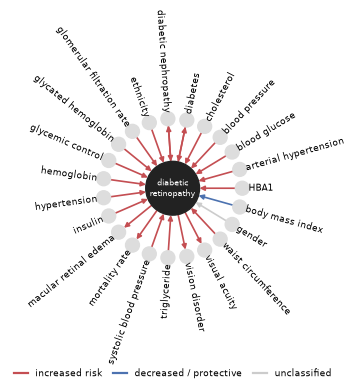

In [8]:
import os
import math
import matplotlib.pyplot as plt
import networkx as nx

SIGN_COLORS = {
    "increased": "#C44E52",
    "decreased": "#4C72B0",
    "null effect": "#999999",
    "mixed": "#8172B2",
    "unclassified": "#CCCCCC",
}
LEGEND_LABELS = {
    "increased": "increased risk",
    "decreased": "decreased / protective",
    "null effect": "null effect",
    "mixed": "mixed evidence",
    "unclassified": "unclassified",
}
ANCHOR = "diabetic retinopathy"

G = nx.DiGraph()
G.add_node(ANCHOR)
for rel in top_for_graph:
    label = rel["_other_concept"]["wikidata_label"]
    G.add_node(label)
    if rel["_direction"] == "upstream":
        G.add_edge(ANCHOR, label, weight=rel["num_studies"], sign=rel["_sign"])
    else:
        G.add_edge(label, ANCHOR, weight=rel["num_studies"], sign=rel["_sign"])

def node_sign(n):
    e = (ANCHOR, n) if G.has_edge(ANCHOR, n) else (n, ANCHOR)
    return G.edges[e]["sign"]

SIGN_ORDER = ["increased", "mixed", "null effect", "unclassified", "decreased"]
others = sorted(
    [n for n in G.nodes if n != ANCHOR],
    key=lambda n: (SIGN_ORDER.index(node_sign(n)), n),
)

# ---- Single ring; labels rotated to run along each node's own ray --------
R, LABEL_GAP = 1.0, 0.09
pos = {ANCHOR: (0.0, 0.0)}
labels = []  # (x, y, text, rotation_deg, ha)
for i, n in enumerate(others):
    theta = 2 * math.pi * i / len(others)
    pos[n] = (R * math.cos(theta), R * math.sin(theta))
    lx, ly = (R + LABEL_GAP) * math.cos(theta), (R + LABEL_GAP) * math.sin(theta)
    deg = math.degrees(theta)
    if 90 < deg < 270:                     # left half: flip so text reads left-to-right
        labels.append((lx, ly, n, deg - 180, "right"))
    else:
        labels.append((lx, ly, n, deg, "left"))

node_colors = ["#222222" if n == ANCHOR else "#DDDDDD" for n in G.nodes]
node_sizes = [1500 if n == ANCHOR else 100 for n in G.nodes]

DRAW_ORDER = ["increased", "decreased", "null effect", "unclassified", "mixed"]
sorted_edges = sorted(G.edges(), key=lambda e: DRAW_ORDER.index(G.edges[e]["sign"]))
sorted_edge_colors = [SIGN_COLORS[G.edges[e]["sign"]] for e in sorted_edges]

# ---- Draw at final print size (included at 0.65\linewidth = 3.6in) -------
fig, ax = plt.subplots(figsize=(3.6, 3.6))
nx.draw_networkx_edges(
    G, pos, edgelist=sorted_edges, edge_color=sorted_edge_colors,
    width=1.2, arrowsize=7, ax=ax, node_size=node_sizes,
)
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=node_sizes, ax=ax)

for lx, ly, text, rot, ha in labels:
    ax.text(lx, ly, text, rotation=rot, rotation_mode="anchor",
            ha=ha, va="center", fontsize=6.3, color="black")
ax.text(0, 0, "diabetic\nretinopathy", fontsize=6, ha="center", va="center", color="white")

LIM = R + LABEL_GAP + 0.90        # room for the longest rotated label
ax.set_xlim(-LIM, LIM)
ax.set_ylim(-LIM, LIM)
ax.set_aspect("equal")
ax.axis("off")

# ---- Legend: only the sign categories that actually occur, in one row ----
present = {node_sign(n) for n in others}
legend_handles = [
    plt.Line2D([0], [0], color=SIGN_COLORS[s], lw=1.6, label=LEGEND_LABELS[s])
    for s in ["increased", "decreased", "null effect", "mixed", "unclassified"]
    if s in present
]
ax.legend(
    handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, -0.12),
    ncol=len(legend_handles), fontsize=6.5, frameon=False,
    handlelength=1.6, columnspacing=1.2,
)

out_path = os.path.abspath("landscape.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print(f"Saved: {out_path}  ({os.path.getsize(out_path):,} bytes)")

plt.show()

## 6. Visualization as table

For actually working through the list beyond visualizing shape and outliers, the landscape can also be rendered in tabular format. Below is a tabular representation of the graph above, with a row to each concept, sorted by `num_studies` (evidence volume).

**Note:** We use evidence volume as our stand-in for "significance" here rather than p-value, since p-value conflates effect size with sample size and doesn't reliably track which relationships are most worth trusting.

In [9]:
summary_rows = []
for rel in top_for_graph:
    summary_rows.append({
        "connected_concept": rel["_other_concept"]["wikidata_label"],
        "direction": rel["_direction"],
        "sign": rel["_sign"],
        "num_studies": rel["num_studies"],
        "num_findings": rel.get("num_findings"),
        "dominant_statistic_type": rel["_statistic_type"],
    })

summary_df = (
    pd.DataFrame(summary_rows)
    .sort_values("num_studies", ascending=False)
    .reset_index(drop=True)
)
summary_df

,connected_concept,direction,sign,num_studies,num_findings,dominant_statistic_type
0,diabetes,downstream,increased,138,192,odds_ratio
1,glycated hemoglobin,downstream,increased,65,89,odds_ratio
2,blood pressure,downstream,increased,45,73,odds_ratio
3,insulin,downstream,increased,40,53,odds_ratio
4,HBA1,downstream,increased,36,48,hazard_ratio
5,body mass index,downstream,decreased,35,52,odds_ratio
6,gender,downstream,unclassified,28,35,NaN
7,blood glucose,downstream,increased,25,36,odds_ratio
8,hemoglobin,downstream,increased,23,29,odds_ratio
9,glycemic control,downstream,increased,22,30,odds_ratio


## Note on connections

The connections appearing in this model are text-mined signals, not structured, queryable-by-measurement data. For example, **glycemic control** just means that the phrase shows up alongside **diabetic retinopathy** in a paper, and is not yet linked to a mechanistic structured lab-value or genomics source.

## Looking ahead

This notebook showed *what* connects to diabetic retinopathy. In the next demo, **Literature Synthesis**, you'll zoom into one of these connections and ask *how strong* the evidence is. In Part 3, **Hypothesis Generation**, you'll ask the question in its inverse: *What connection **should** exist here that nobody's tested yet?*